# XLS-R 음성 특징의 클래스별 분포 분석

분류기 출력이 아니라 저장된 **1920차원 XLS-R mean-pooled embedding** 자체를 분석한다.

확인할 내용:

- PCA/UMAP에서 언어 클래스별 군집이 형성되는가?
- 언어보다 SpeakerID에 의해 더 강하게 군집화되는가?
- 클래스 중심(centroid) 간 어떤 언어가 가까운가?
- 분류기 학습 없이 nearest-centroid 기준으로 어느 정도 구분되는가?

> 전체 데이터는 매우 크므로 test split에서 클래스·화자 균형 샘플링을 수행한다.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler, normalize

FOREIGN_DIR = Path('$NATIONALITY_OUTPUTS/feature_resplit_61_merged6_seed42_target_counts')
KOREAN_DIR = Path('$SPEECH_AI_DATA/taeho/korean_native_features/sec12')
OUTPUT_DIR = Path('$NATIONALITY_OUTPUTS/xlsr_embedding_distribution_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 노트북과 함께 저장된 한글 폰트를 Matplotlib에 직접 등록
KOREAN_FONT_PATH = Path('$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf')
if not KOREAN_FONT_PATH.exists():
    raise FileNotFoundError(f'한글 폰트가 없습니다: {KOREAN_FONT_PATH}')
font_manager.fontManager.addfont(str(KOREAN_FONT_PATH))
korean_font_name = font_manager.FontProperties(fname=str(KOREAN_FONT_PATH)).get_name()
plt.rcParams['font.family'] = korean_font_name
plt.rcParams['font.sans-serif'] = [korean_font_name]
plt.rcParams['axes.unicode_minus'] = False

SPLIT = 'test'
INCLUDE_KOREAN = True       # False면 기존 61개 외국어 클래스만 분석
MAX_PER_CLASS = 500         # 클래스당 최대 샘플
MAX_PER_SPEAKER = 50        # 한 화자가 시각화를 지배하지 않도록 제한
RANDOM_SEED = 42
PCA_COMPONENTS = 50

print('Matplotlib Korean font:', korean_font_name)
print('Foreign feature:', FOREIGN_DIR / f'{SPLIT}.npz')
print('Include Korean:', INCLUDE_KOREAN)

Matplotlib Korean font: Noto Sans KR
Foreign feature: $NATIONALITY_OUTPUTS/feature_resplit_61_merged6_seed42_target_counts/test.npz
Include Korean: True


In [2]:
def load_feature_split(directory, split):
    data = np.load(directory / f'{split}.npz', allow_pickle=True)
    return {
        'X': data['X'],
        'y': data['y'].astype(np.int64),
        'speaker': data['speaker'].astype(str),
    }


foreign = load_feature_split(FOREIGN_DIR, SPLIT)
id2label = json.loads((FOREIGN_DIR / 'id2label.json').read_text(encoding='utf-8'))
labels = [id2label[str(i)] for i in range(61)]

X_all = foreign['X']
y_all = foreign['y']
speaker_all = foreign['speaker']

if INCLUDE_KOREAN:
    korean = load_feature_split(KOREAN_DIR, SPLIT)
    X_all = np.concatenate([X_all, korean['X']], axis=0)
    y_all = np.concatenate([y_all, np.full(len(korean['X']), 61, dtype=np.int64)])
    speaker_all = np.concatenate([speaker_all, korean['speaker']])
    labels.append('한국어_모국어')

print('X:', X_all.shape, X_all.dtype)
print('classes present:', len(np.unique(y_all)))
print('speakers:', len(np.unique(speaker_all)))

X: (137977, 1920) float16
classes present: 42
speakers: 456


## 클래스·화자 균형 샘플링

먼저 각 화자에서 최대 `MAX_PER_SPEAKER`개만 뽑고, 이후 각 클래스에서 최대 `MAX_PER_CLASS`개를 뽑는다.

In [3]:
def balanced_indices(y, speakers, max_per_class, max_per_speaker, seed=42):
    rng = np.random.default_rng(seed)
    selected = []
    for class_id in np.unique(y):
        class_indices = np.flatnonzero(y == class_id)
        class_selected = []
        class_speakers = speakers[class_indices]
        for speaker in np.unique(class_speakers):
            indices = class_indices[class_speakers == speaker]
            if len(indices) > max_per_speaker:
                indices = rng.choice(indices, max_per_speaker, replace=False)
            class_selected.extend(indices.tolist())
        class_selected = np.asarray(class_selected, dtype=np.int64)
        if len(class_selected) > max_per_class:
            class_selected = rng.choice(class_selected, max_per_class, replace=False)
        selected.extend(class_selected.tolist())
    selected = np.asarray(selected, dtype=np.int64)
    rng.shuffle(selected)
    return selected


sample_indices = balanced_indices(
    y_all, speaker_all, MAX_PER_CLASS, MAX_PER_SPEAKER, RANDOM_SEED
)
X = X_all[sample_indices].astype(np.float32)
y = y_all[sample_indices]
speakers = speaker_all[sample_indices]
label_names = np.asarray([labels[class_id] for class_id in y])

sample_summary = pd.DataFrame({'class_id': y, 'class': label_names, 'speaker': speakers})
class_summary = sample_summary.groupby(['class_id', 'class']).agg(
    samples=('speaker', 'size'), speakers=('speaker', 'nunique')
).reset_index()
display(class_summary)
print('sampled:', len(X), '| classes:', len(np.unique(y)), '| speakers:', len(np.unique(speakers)))

,class_id,class,samples,speakers
0,0,중국어,500,39
1,1,일본어,500,26
2,2,베트남어,500,30
3,3,태국어,500,21
4,4,몽골어,500,11
5,5,러시아어,301,7
6,6,영어,500,17
7,7,미얀마어,306,8
8,8,인도네시아어,200,4
9,9,광동어,116,3


sampled: 5835 | classes: 42 | speakers: 400


## PCA

표준화 후 PCA를 적용한다. 2차원 그림은 전체 구조를 단순화한 것이므로 겹쳐 보인다고 원래 1920차원에서 분리되지 않는다는 뜻은 아니다.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
n_components = min(PCA_COMPONENTS, len(X) - 1, X.shape[1])
pca = PCA(n_components=n_components, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_scaled)

print(f'PCA {n_components}개 누적 설명분산: {pca.explained_variance_ratio_.sum():.3f}')
print(f'PC1+PC2 설명분산: {pca.explained_variance_ratio_[:2].sum():.3f}')

PCA 50개 누적 설명분산: 0.838
PC1+PC2 설명분산: 0.467


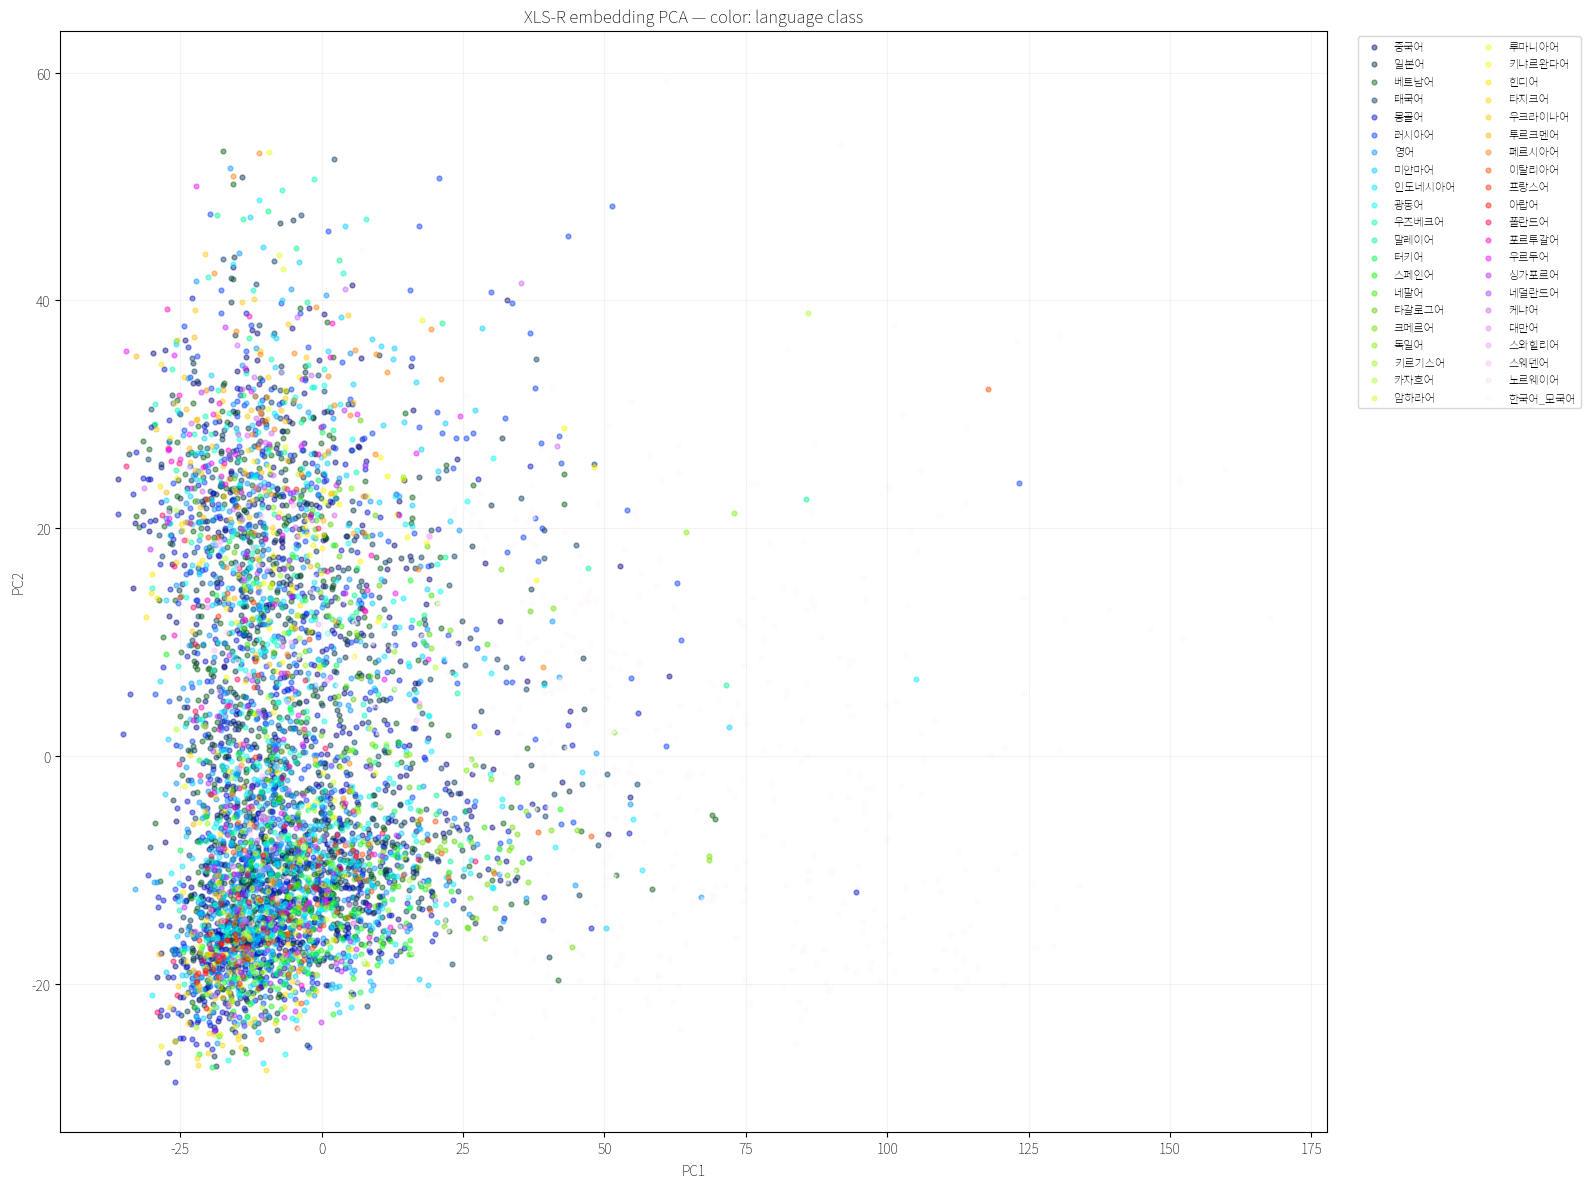

In [5]:
fig, ax = plt.subplots(figsize=(16, 12))
present_classes = np.unique(y)
cmap = plt.get_cmap('gist_ncar', len(present_classes))

for color_index, class_id in enumerate(present_classes):
    mask = y == class_id
    ax.scatter(
        X_pca[mask, 0], X_pca[mask, 1], s=12, alpha=0.45,
        color=cmap(color_index), label=labels[class_id], rasterized=True
    )

ax.set_title('XLS-R embedding PCA — color: language class')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, ncol=2)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'pca_by_class.png', dpi=180, bbox_inches='tight')
plt.show()

## 주요 클래스만 확대

클래스가 너무 많으면 그림 판독이 어려우므로 샘플 수가 많은 상위 클래스를 별도로 확인한다.

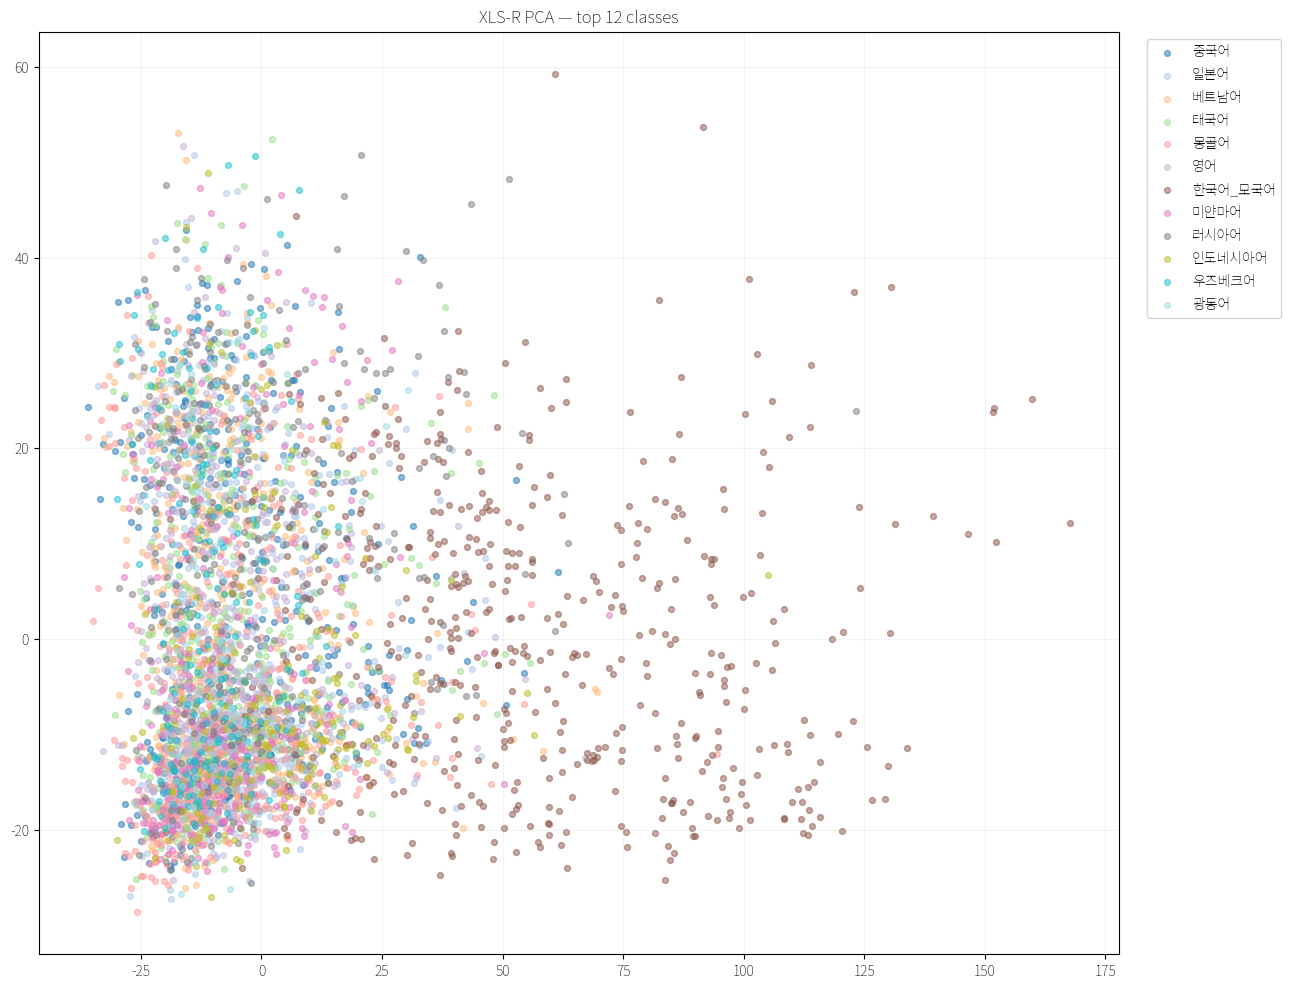

In [6]:
TOP_CLASSES = 12
top_class_ids = class_summary.nlargest(TOP_CLASSES, 'samples')['class_id'].to_numpy()
major_mask = np.isin(y, top_class_ids)

fig, ax = plt.subplots(figsize=(13, 10))
cmap = plt.get_cmap('tab20', len(top_class_ids))
for color_index, class_id in enumerate(top_class_ids):
    mask = y == class_id
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=18, alpha=0.5,
               color=cmap(color_index), label=labels[class_id], rasterized=True)
ax.set_title(f'XLS-R PCA — top {TOP_CLASSES} classes')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(alpha=0.15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'pca_top_classes.png', dpi=180, bbox_inches='tight')
plt.show()

## 클래스 군집과 화자 군집 비교

Silhouette score는 -1~1 범위이며 높을수록 같은 그룹끼리 가깝고 다른 그룹과 멀다는 뜻이다.

- class score가 높으면 언어별 특징이 강함
- speaker score가 더 높으면 언어보다 화자 개인 특성이 강할 가능성

화자당 샘플이 2개 이상인 화자만 speaker score에 포함한다.

In [11]:
# 계산량을 제한하면서 고차원 구조를 보존하기 위해 PCA 50차원을 사용
silhouette_sample_size = min(5000, len(X_pca))
class_silhouette = silhouette_score(
    X_pca, y, metric='euclidean', sample_size=silhouette_sample_size,
    random_state=RANDOM_SEED
)

speaker_counts = pd.Series(speakers).value_counts()
eligible_speakers = speaker_counts[speaker_counts >= 2].index
speaker_mask = np.isin(speakers, eligible_speakers)
speaker_sample_size = min(5000, int(speaker_mask.sum()))
speaker_silhouette = silhouette_score(
    X_pca[speaker_mask], speakers[speaker_mask], metric='euclidean',
    sample_size=speaker_sample_size, random_state=RANDOM_SEED
)

silhouette_df = pd.DataFrame([
    {'grouping': 'language class', 'score': class_silhouette,
     'samples': len(X_pca), 'groups': len(np.unique(y))},
    {'grouping': 'speaker', 'score': speaker_silhouette,
     'samples': int(speaker_mask.sum()), 'groups': len(eligible_speakers)},
])
display(silhouette_df)

if class_silhouette > speaker_silhouette:
    print('해석: 이 샘플에서는 화자보다 언어 클래스 군집 신호가 상대적으로 더 강합니다.')
else:
    print('해석: 이 샘플에서는 언어보다 화자 개인 군집 신호가 상대적으로 더 강합니다.')

,grouping,score,samples,groups
0,language class,-0.137061,5835,42
1,speaker,-0.076343,5784,349


해석: 이 샘플에서는 언어보다 화자 개인 군집 신호가 상대적으로 더 강합니다.


## 클래스 중심 간 유사도

각 클래스의 PCA embedding 평균을 중심점으로 삼아 cosine similarity를 계산한다. 값이 클수록 XLS-R 공간에서 중심이 가깝다.

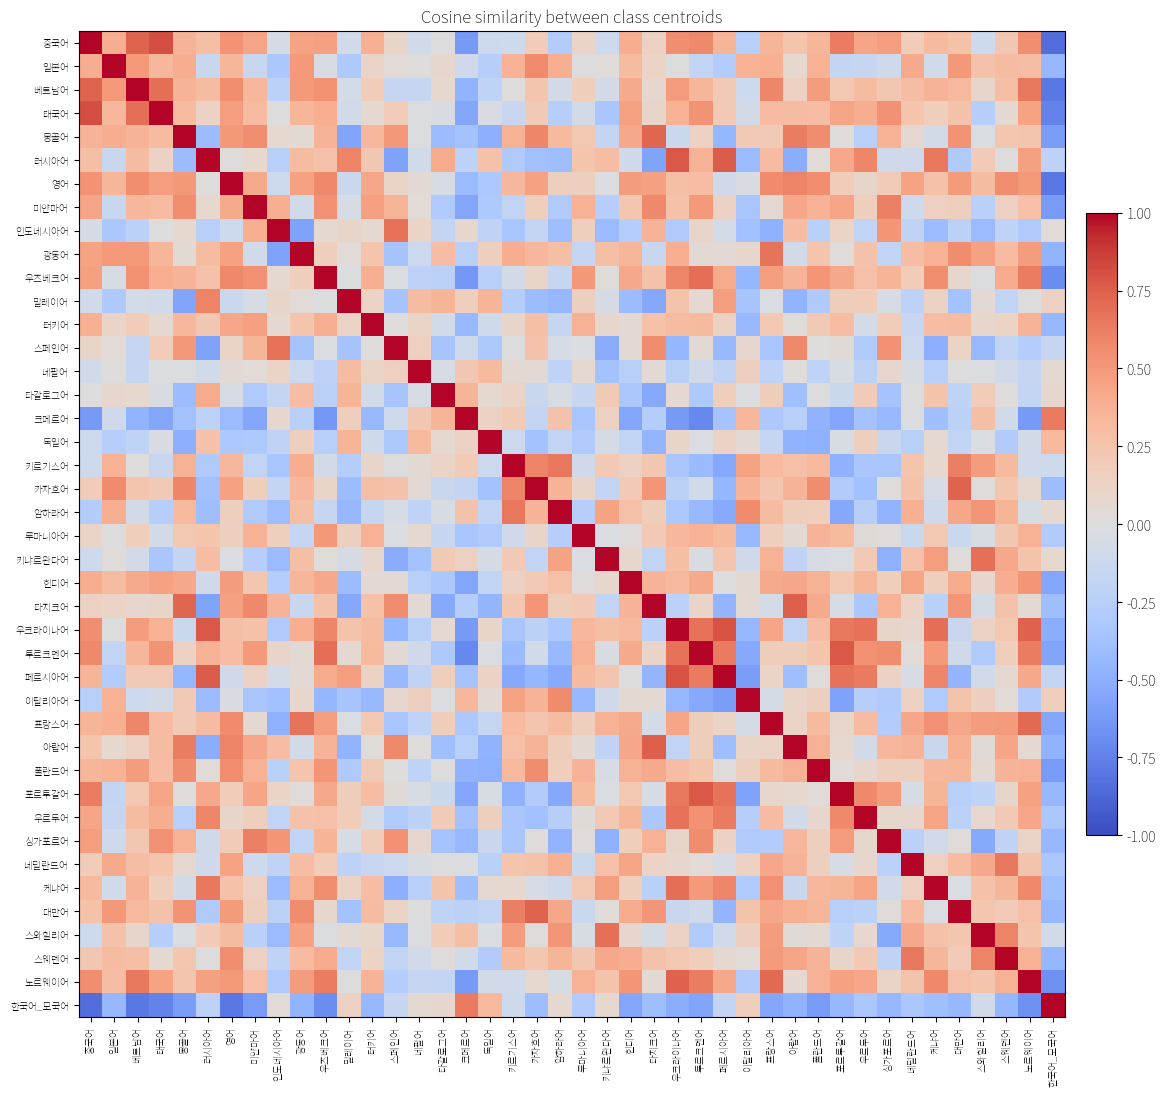

,class_a,class_b,cosine_similarity
2,중국어,태국어,0.804809
726,우크라이나어,페르시아어,0.799466
214,러시아어,우크라이나어,0.779109
746,투르크멘어,포르투갈어,0.773785
216,러시아어,페르시아어,0.761081
713,타지크어,아랍어,0.746676
739,우크라이나어,노르웨이어,0.741908
625,카자흐어,대만어,0.731047
1,중국어,베트남어,0.730239
177,몽골어,타지크어,0.724364


In [12]:
present_classes = np.unique(y)
centroids = np.vstack([X_pca[y == class_id].mean(axis=0) for class_id in present_classes])
centroid_similarity = cosine_similarity(centroids)
centroid_labels = [labels[class_id] for class_id in present_classes]

fig_size = max(10, len(centroid_labels) * 0.28)
fig, ax = plt.subplots(figsize=(fig_size, fig_size))
image = ax.imshow(centroid_similarity, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(centroid_labels)), centroid_labels, rotation=90, fontsize=7)
ax.set_yticks(range(len(centroid_labels)), centroid_labels, fontsize=7)
ax.set_title('Cosine similarity between class centroids')
fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_centroid_similarity.png', dpi=180, bbox_inches='tight')
plt.show()

pairs = []
for i in range(len(centroid_labels)):
    for j in range(i + 1, len(centroid_labels)):
        pairs.append({
            'class_a': centroid_labels[i], 'class_b': centroid_labels[j],
            'cosine_similarity': centroid_similarity[i, j]
        })
pair_df = pd.DataFrame(pairs).sort_values('cosine_similarity', ascending=False)
display(pair_df.head(30))

## 분류기 학습 없는 Leave-one-out nearest-centroid 검사

각 샘플 자신을 제외한 같은 클래스 중심을 만들고 가장 가까운 클래스 중심을 찾는다. Linear classifier 성능과 동일한 지표는 아니며, embedding 자체의 단순 분리 가능성을 보는 진단값이다.

In [13]:
present_classes = np.unique(y)
X_unit = normalize(X_pca)
class_sums = {class_id: X_unit[y == class_id].sum(axis=0) for class_id in present_classes}
class_counts = {class_id: int((y == class_id).sum()) for class_id in present_classes}
predicted = []

for row, true_class in zip(X_unit, y):
    candidate_centroids = []
    for class_id in present_classes:
        count = class_counts[class_id]
        if class_id == true_class and count > 1:
            centroid = (class_sums[class_id] - row) / (count - 1)
        else:
            centroid = class_sums[class_id] / count
        candidate_centroids.append(centroid)
    candidate_centroids = normalize(np.vstack(candidate_centroids))
    predicted.append(present_classes[np.argmax(candidate_centroids @ row)])

predicted = np.asarray(predicted)
centroid_rows = []
for class_id in present_classes:
    mask = y == class_id
    centroid_rows.append({
        'class_id': int(class_id),
        'class': labels[class_id],
        'n': int(mask.sum()),
        'nearest_centroid_top1': float(np.mean(predicted[mask] == class_id)),
    })
centroid_result_df = pd.DataFrame(centroid_rows).sort_values(
    'nearest_centroid_top1', ascending=False
)
print('전체 nearest-centroid accuracy:', float(np.mean(predicted == y)))
display(centroid_result_df)

전체 nearest-centroid accuracy: 0.30008568980291345


,class_id,class,n,nearest_centroid_top1
20,20,암하라어,2,1.000000
30,32,아랍어,31,1.000000
24,24,타지크어,50,0.980000
35,39,네덜란드어,21,0.952381
41,61,한국어_모국어,500,0.918000
28,28,이탈리아어,50,0.900000
16,16,크메르어,50,0.900000
37,46,대만어,8,0.875000
29,31,프랑스어,18,0.833333
22,22,키냐르완다어,50,0.800000


## 선택 사항: UMAP

`umap-learn`이 설치된 환경에서는 아래 셀을 실행한다. 현재 커널에 없다면 PCA 분석은 정상적으로 계속 사용할 수 있다.

In [14]:
try:
    import umap
except ImportError:
    print('UMAP 미설치: pip install umap-learn')
else:
    reducer = umap.UMAP(
        n_neighbors=30, min_dist=0.15, metric='cosine',
        random_state=RANDOM_SEED
    )
    X_umap = reducer.fit_transform(X_pca)
    fig, ax = plt.subplots(figsize=(16, 12))
    cmap = plt.get_cmap('gist_ncar', len(present_classes))
    for color_index, class_id in enumerate(present_classes):
        mask = y == class_id
        ax.scatter(X_umap[mask, 0], X_umap[mask, 1], s=12, alpha=0.5,
                   color=cmap(color_index), label=labels[class_id], rasterized=True)
    ax.set_title('XLS-R embedding UMAP — color: language class')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'umap_by_class.png', dpi=180, bbox_inches='tight')
    plt.show()

UMAP 미설치: pip install umap-learn


In [ ]:
embedding_df = pd.DataFrame({
    'class_id': y,
    'class': label_names,
    'speaker': speakers,
    'pc1': X_pca[:, 0],
    'pc2': X_pca[:, 1],
})
embedding_df.to_csv(OUTPUT_DIR / 'sampled_pca_embeddings.csv', index=False, encoding='utf-8-sig')
class_summary.to_csv(OUTPUT_DIR / 'sample_summary.csv', index=False, encoding='utf-8-sig')
silhouette_df.to_csv(OUTPUT_DIR / 'silhouette_scores.csv', index=False, encoding='utf-8-sig')
pair_df.to_csv(OUTPUT_DIR / 'class_centroid_similarity_pairs.csv', index=False, encoding='utf-8-sig')
centroid_result_df.to_csv(OUTPUT_DIR / 'nearest_centroid_results.csv', index=False, encoding='utf-8-sig')
print('saved to:', OUTPUT_DIR)